# Real birefringent specimen: calibrated four-state polarimetry

This notebook actively reconstructs the first acquired time point at all three stage positions and all sixteen defocus planes of a real Kazansky calibration specimen. It is not a cell or a synthetic target. The four required outputs are effective retardance, pi-periodic slow-axis angle, background-relative intensity, and retained polarization. Independent empty-field images and calibration are public inputs.

For circular input, the specimen Stokes vector is $s=T(1,P\sin\delta\sin2\theta,-P\sin\delta\cos2\theta,P\cos\delta)$, where $\delta$ and $\theta$ are in radians, $T$ is relative intensity, and $P$ is unitless polarization retention. Raw analyzer data satisfy $I=A M_{bg}s+d1+\eta$; $A$ is the supplied instrument response, $M_{bg}$ is the empty-field Mueller map, $d=100.58$ ADU is independently measured dark offset, and $\eta$ is noise. All native detector pixels are retained.

After subtracting dark offset, apply $A^+$ to recover Stokes vectors. Estimate the background's attenuating-retarder Mueller matrix from its own Stokes vector, invert each 4 by 4 matrix, and correct the sample Stokes vector. Let $L=\sqrt{s_1^2+s_2^2+s_3^2}$. The analytic weak-retardance inverse is $\delta=\arcsin(\sqrt{s_1^2+s_2^2}/L)$, $\theta=\mathrm{atan2}(s_1,-s_2)/2$ modulo pi, $T=s_0$, and $P=L/s_0$. No flip, rotation, clipping or smoothing is performed.

Lateral pitch and background exposure are not reliably deposited, so lateral distances use detector pixels and $T$ is not claimed as absolute optical transmission. Values $P>1$ are retained as measurement/model limitations. Defocus planes are independent effective images, not a local three-dimensional birefringence tensor. This selects waveorder's Stokes/ADR inverse; phase-from-defocus is a different output contract and is not implied.

In [1]:
from pathlib import Path
import os,sys,time,json,platform,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1'
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/main.py').exists())
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,figures,export_figures,relative_l2
try:
    import torch
    torch.set_num_threads(1)
except ImportError:
    pass
print('Python',platform.python_version(),'NumPy',np.__version__,'CPU',platform.platform())
data=load_data(root/'data/raw_data.npz')
start=time.perf_counter()
fresh=reconstruct(data)
reconstruction_runtime=time.perf_counter()-start
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/cleaned.npz',**fresh)
print('Fresh complete benchmark reconstruction seconds:',reconstruction_runtime)
print({k:(v.shape,str(v.dtype)) for k,v in fresh.items()})


Python 3.11.11 NumPy 2.4.6 CPU Windows-10-10.0.26200-SP0
Fresh complete benchmark reconstruction seconds: 0.1558645002078265
{'reconstruction': ((1, 3, 16, 128, 256), 'float32'), 'orientation': ((1, 3, 16, 128, 256), 'float32'), 'transmittance': ((1, 3, 16, 128, 256), 'float32'), 'depolarization': ((1, 3, 16, 128, 256), 'float32')}


## Independent numerical comparison and evaluation

The reference below was captured by running the original source on exactly these observations before local extraction. It is identified as an upstream method result; no independently measured specimen truth is available. Every required quantity is evaluated.

In [2]:
upstream=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/'output/reconstruction.npz')
assert exit_code==0,report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report,indent=2))

original_mapping={'reconstruction': 'output_retardance', 'orientation': 'output_orientation', 'transmittance': 'output_transmittance', 'depolarization': 'output_depolarization'}
print("Direct original-versus-fresh array comparisons:", {k:relative_l2(fresh[k],upstream[v][None]) for k,v in original_mapping.items()})


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_relative_l2": 4.515835926124896e-08,
    "orientation_angular_rmse": 2.3716340610362295e-08,
    "transmittance_relative_l2": 0.0,
    "depolarization_relative_l2": 6.4846591706579635e-09
  },
  "thresholds": {
    "reconstruction_relative_l2": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "orientation_angular_rmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "transmittance_relative_l2": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "depolarization_relative_l2": {
      "comparison": "<=",
      "boundary": 2e-05
    }
  },
  "errors": []
}
Direct original-versus-fresh array comparisons: {'reconstruction': 4.515835926124896e-08, 'orientation': 1.6562187989890606e-08, 'transmittance': 0.0, 'depolarization': 6.4846591706579635e-09}


## Fresh experiment suite

All alternatives below are actively recomputed with local modules. No archived output is presented as a new alternative. Numerical source values are retained for the displayed experiments.

In [3]:
experiment_start=time.perf_counter()
experiments=run_experiments(data,fresh)
experiment_runtime=time.perf_counter()-experiment_start
np.savez_compressed(root/'notebooks/reference_outputs/experiments.npz',**experiments)
plots=figures(data,fresh,upstream,experiments)
plt.close('all')  # Keep figure objects; scientific sections display each plate once.
print('Additional experiment seconds:',experiment_runtime)
print({k:v.shape for k,v in experiments.items()})


Additional experiment seconds: 0.47529869992285967
{'uncorrected_retardance': (1, 3, 16, 128, 256), 'uncorrected_orientation': (1, 3, 16, 128, 256), 'dark_offsets': (3,), 'dark_sensitivity': (3, 2), 'dop_above_one': (3, 16), 'z_median_retardance': (3, 16), 'z_median_transmittance': (3, 16)}


### Analyzer observations

The four recorded analyzer channels have a shared raw ADU scale. No image is generated or substituted. The full recording has no saturated detector samples; native detector coordinates remain explicit.

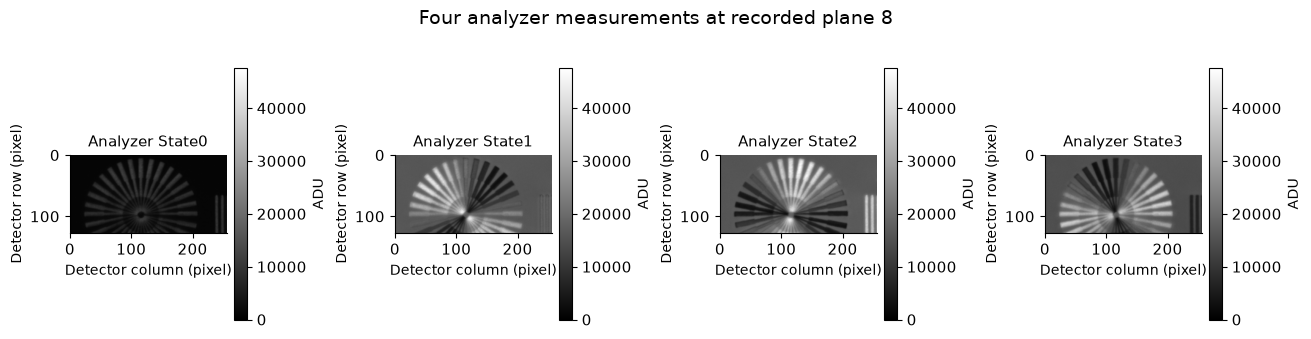

In [4]:
display(plots['01_analyzer_observations'])
plt.close(plots['01_analyzer_observations'])

### Quantitative polarimetry

Retardance maps, slow-axis glyphs, relative intensity, and polarization retention are reconstructed for all positions. Glyphs use a display threshold of 0.03 radian for readability only; all pixel angles remain in the saved output and are evaluated with continuous physical weighting. The P display includes values above one.

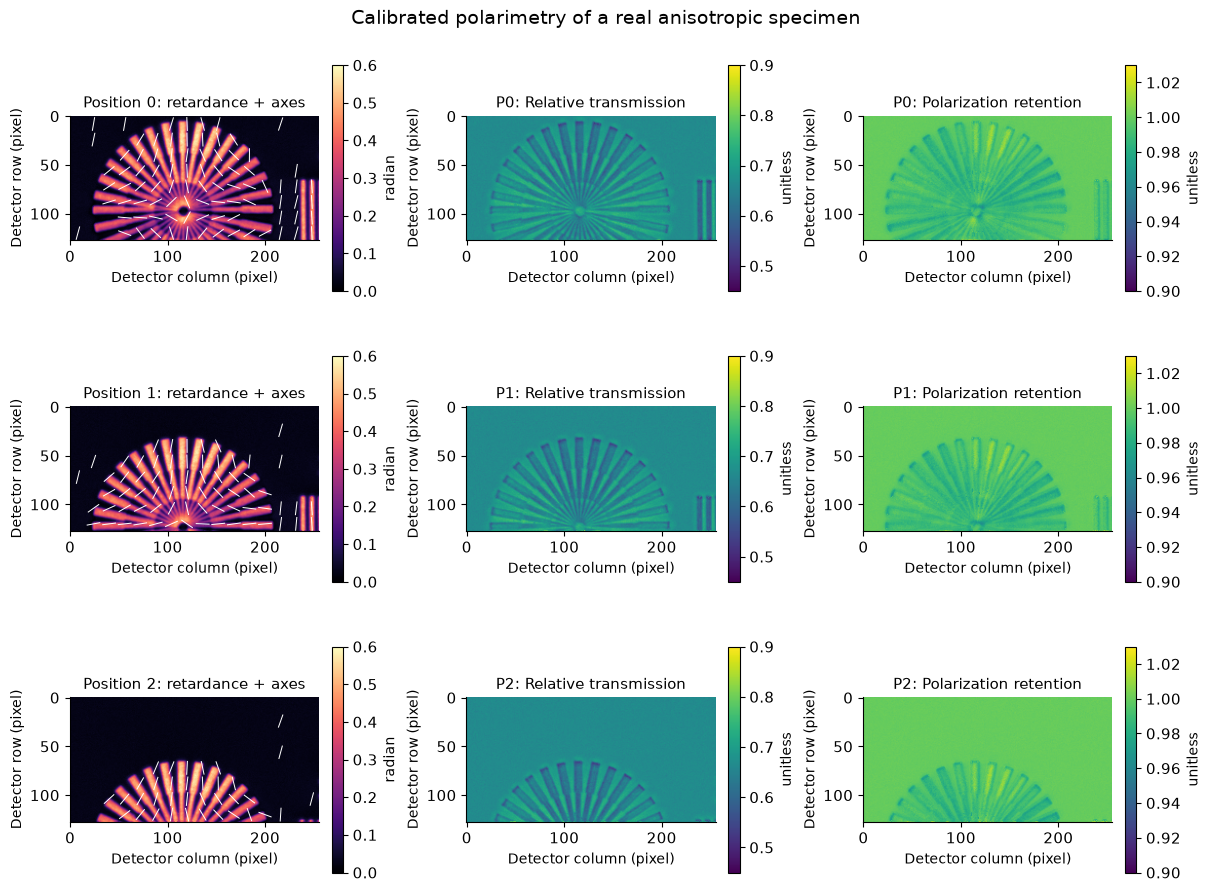

In [5]:
display(plots['02_quantitative_polarimetry'])
plt.close(plots['02_quantitative_polarimetry'])

### Background and numerical parity

The uncorrected case is actually rerun. Its difference from calibrated reconstruction tests instrumental-background sensitivity. The original independent execution is a method measurement, not material truth. The histogram retains all noisy P estimates, including physically inadmissible values.

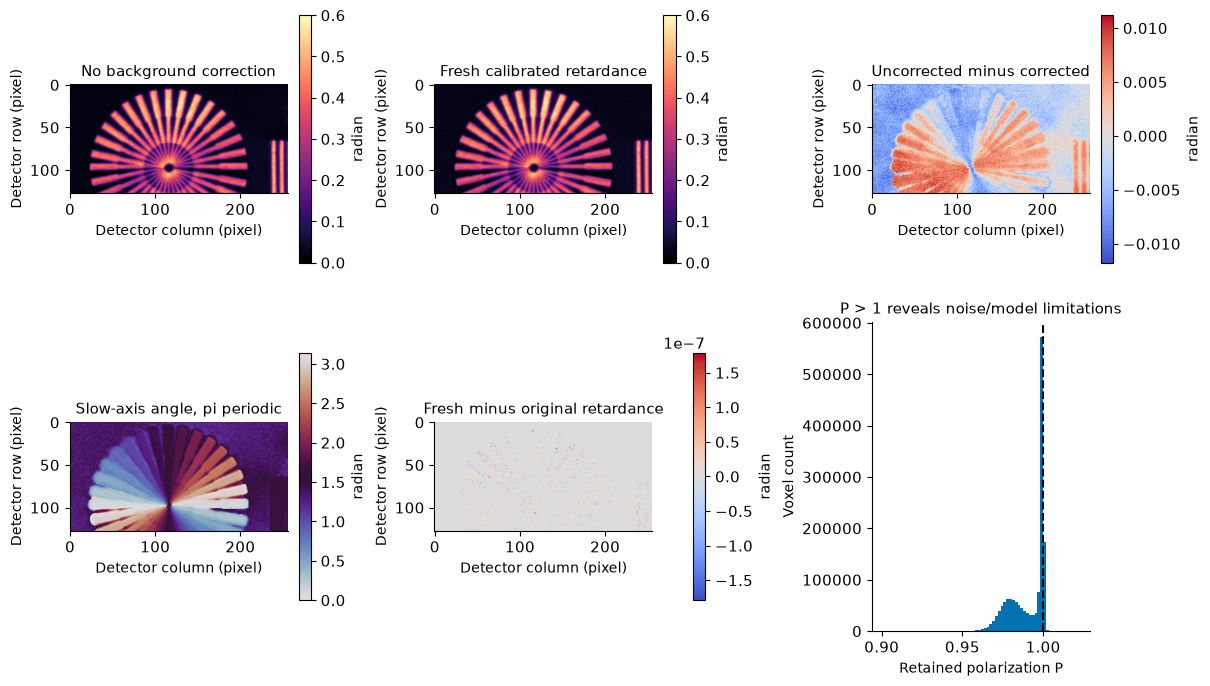

In [6]:
display(plots['03_background_and_numerical_parity'])
plt.close(plots['03_background_and_numerical_parity'])

### Defocus and calibration

All sixteen defocus planes and three positions contribute to the summaries. Dark offsets of 80.58 and 120.58 ADU are explicit perturbation experiments around independently measured 100.58 ADU, not target-fitted corrections. Defocus dependence bounds the claim of effective two-dimensional retarder imaging.

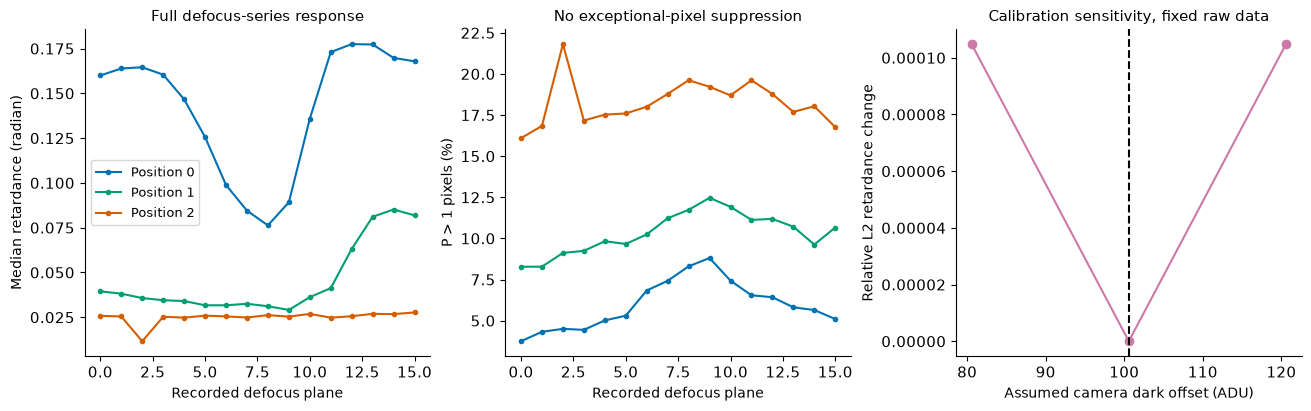

In [7]:
display(plots['04_defocus_and_calibration'])
plt.close(plots['04_defocus_and_calibration'])

## Conclusion and review record

Fresh original-method agreement validates the local mathematical extraction on these observations. The actual observation and calibration experiments above delimit the scientific interpretation; agreement with a standard reconstruction does not establish hidden physical truth. The notebook keeps physical failures and uncertain estimates visible.

In [8]:
measurement={'reconstruction_runtime_s':reconstruction_runtime,'experiment_runtime_s':experiment_runtime,
             'python':platform.python_version(),'numpy':np.__version__,'metrics':report['metrics']}
(root/'notebooks/reference_outputs/measurement.json').write_text(json.dumps(measurement,indent=2),encoding='utf8')
# An optional maintainer-owned export directory keeps publication figures out of the task runtime.
if os.environ.get('IMAGING_EXPORT_DIR'):
    values={**{k:v for k,v in fresh.items()},**{'experiment_'+k:v for k,v in experiments.items()}}
    export_figures(plots,Path(os.environ['IMAGING_EXPORT_DIR']),values)
print(json.dumps(measurement,indent=2))


{
  "reconstruction_runtime_s": 0.1558645002078265,
  "experiment_runtime_s": 0.47529869992285967,
  "python": "3.11.11",
  "numpy": "2.4.6",
  "metrics": {
    "reconstruction_relative_l2": 4.515835926124896e-08,
    "orientation_angular_rmse": 2.3716340610362295e-08,
    "transmittance_relative_l2": 0.0,
    "depolarization_relative_l2": 6.4846591706579635e-09
  }
}
